In [97]:
%load_ext autoreload
%autoreload 2
import cv2 as cv
import numpy as np
from matplotlib import pyplot as plt
from collections import deque


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


### Check if it manages to load video

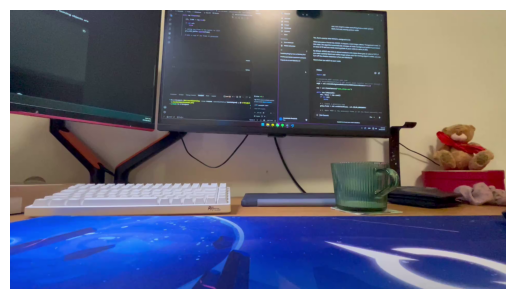

In [98]:
cap = cv.VideoCapture("test.mov")

if not cap.isOpened():
    print("Error opening video")

# read the first frame if there is a frame ret = true
ret, frame = cap.read()

if ret:
    frame_rgb = cv.cvtColor(frame, cv.COLOR_BGR2RGB)

    plt.imshow(frame_rgb)
    plt.axis("off")
    plt.show()



    

### ROI definition

In [99]:
def roi(frame):
    pts = np.array([
        [355, 153],   # Top left
        [1578, 113],  # Top right
        [1621, 1020], # Bottom right
        [322, 1013]   # Bottom left
    ])

    # Needed for OpenCV to understand coordinates as a list
    pts = pts.reshape((-1, 1, 2))

    # Makes black and white mask:
    mask = np.zeros(frame.shape, dtype = np.uint8)
    cv.fillPoly(mask, [pts], (255,255,255))

    # Black = delete video pixels of original frame; White = let pixels through
    rect_img = cv.bitwise_and(frame, mask)

    return rect_img



### MOG2 definition

In [ ]:
def mog2(frame, fgbg_mog2):
    fgmask = fgbg_mog2.apply(frame)

    # Size of the filter
    # TODO: adjust kernel in real world situation
    kernel = np.ones((5,5), np.uint8)

    fgmask_erode = cv.erode(fgmask, kernel, iterations = 1)
    fgmask_final = cv.dilate(fgmask_erode, kernel, iterations = 1)

    return fgmask_final

### Object detection logic

In [ ]:
def object_detect(mask, color_frame):
    contours, hierarchy = cv.findContours(mask, cv.RETR_TREE, cv.CHAIN_APPROX_NONE)
    detected = False

    for contour in contours:
        area = cv.contourArea(contour)

        #TODO: adjust in real world situation
        # If object bigger than 50 pixels
        if area > 50:
            detected = True
            cv.drawContours(color_frame, [contour], -1, (0, 255, 0), 2)

    return detected, color_frame


### Make a circular ring buffer to store frames 

In [ ]:
pre_roll_buffer = deque(maxlen=100)
filter_buffer = deque()

# for MOG2 background subtraction
fgbg_mog2 = cv.createBackgroundSubtractorMOG2(history=500, varThreshold=100, detectShadows=False)
# VideoWriter needs exact width, height and FPS to create a valid video
width = int(cap.get(cv.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv.CAP_PROP_FRAME_HEIGHT))
fps = cap.get(cv.CAP_PROP_FPS)

#fourcc - four character code: used to identify which codec program should use to shirnk the file
fourcc = cv.VideoWriter_fourcc(*'mp4v')

# Filtered video to check if it's working correctly
out_filter = cv.VideoWriter("out_filter.mp4", fourcc, fps, (width, height), isColor=False)

print("Starting video feed...")

object_detected = False
is_recording = False
out = None
frame_count = 0
frames_since_last_detection = 0

while cap.isOpened():
    ret, frame = cap.read()
    if not ret:
        break

    frame_count += 1 
    rect_image = roi(frame)


    # MOG2 logic
    final_mask = mog2(rect_image, fgbg_mog2)
    out_filter.write(final_mask)
    
    # Run the detection
    object_detected, tracked_frame = object_detect(final_mask, frame)


    # Recording 60 frames after detecting
    if object_detected:
        frames_since_last_detection = 0 
    elif is_recording:
        frames_since_last_detection += 1 

    # 1. BUFFER OR RECORD
    if not is_recording:
        # If the alarm hasn't tripped, hold frames
        pre_roll_buffer.append(tracked_frame)
    else:
        # If the alarm is tripped, write every new frame directly to the hard drive
        out.write(tracked_frame)

    # Trigger the "alarm", object has been detectet 
    # Frame count > 0 to give MOG2 time to stabalize
    if object_detected and frame_count > 30 and not is_recording: 
        is_recording = True 

        out = cv.VideoWriter("out.mp4", fourcc, fps, (width, height))
        
        for buffered_frame in pre_roll_buffer:
            out.write(buffered_frame)
            
        pre_roll_buffer.clear()

    # Stoping the alarm 
    if is_recording and frames_since_last_detection > 60:
        is_recording = False
        # out.release so it can be sent as a video
        out.release() 
        out = None 
        frames_since_last_detection = 0

        #TODO: notification feature here
        # Use threads so that camera doesn't freeze

# Only for PC similuation, real camera feed won't get here on normal run
if out is not None:
    out.release()
    print("Color video saved as 'out.mp4'.")

out_filter.release()
cap.release() 
print("Finished completely. Exiting...")

Starting video feed...
Color video saved as 'out.mp4'.
Finished completely. Exiting...
